In [1]:
from itertools import product
import pickle
import json
import h5py
from tqdm import tqdm, trange

import numpy as np
from numpy.linalg import eigh
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Ellipse
from corner import corner as corner_plot

from scipy import special, stats
from scipy.stats import gaussian_kde, chi2
from scipy.interpolate import RegularGridInterpolator

import os

from local_utils import delaunaytor
from popsummary.popresult import PopulationResult
from astropy.cosmology import Planck15
from astropy import units as u


plt.style.use("tableau-colorblind10")
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.size"] = 14
plt.rcParams["text.usetex"] = True

# GW events

## From gwax

In [2]:
parameter_keys_1 = ["m1", "z", "q", "chi1", "chi2", "cos_tilt_1", "cos_tilt_2"]

data_file = np.load("../gwax_samples/gwtc4_samples.npz")
observed_events_1 = np.vstack([data_file[key + "s"] for key in parameter_keys_1]).T
num_events_1 = data_file["nevents"]
num_samples_1 = data_file["nsamples"]
event_priors_1 = data_file["priors"]
print(
        f"Running with {num_events_1} events × {num_samples_1} samples = {num_events_1*num_samples_1} total samples"
    )

event_barycenters_1 = observed_events_1.reshape(
    (num_events_1, num_samples_1, observed_events_1.shape[-1])
).mean(axis=1)

Running with 153 events × 3194 samples = 488682 total samples


## From mock

In [3]:
parameter_keys_2 = ["m1", "z", "q"]

data_file = np.load("./datasets/samples_no_mass_gap_pop_153_evs_5000_samples_sample_in_q_zmax_1.5_seed_1.npz")
observed_events_2 = np.vstack([data_file[key + "_obs"] for key in parameter_keys_2]).T
num_samples_2 = int(data_file["nsamples_ev"])
num_events_2 = int(observed_events_2.shape[0] /num_samples_2)
event_priors_2 = data_file["priors"]
print(
        f"Running with {num_events_2} events × {num_samples_2} samples = {num_events_2*num_samples_2} total samples"
    )

event_barycenters_2 = observed_events_2.reshape(
    (num_events_2, num_samples_2, observed_events_2.shape[-1])
).mean(axis=1)

Running with 153 events × 5000 samples = 765000 total samples


## Look at event barycenters

Number of events from gwax file with q~0.2: 0
Number of events from mock file with q~0.2: 0


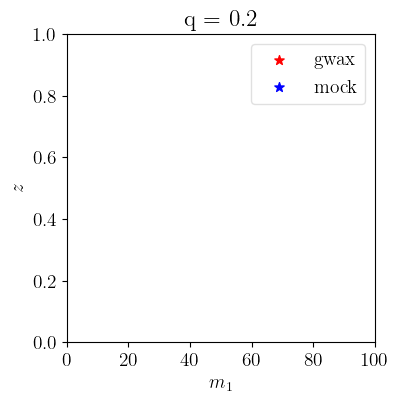

Number of events from gwax file with q~0.5: 10
Number of events from mock file with q~0.5: 11


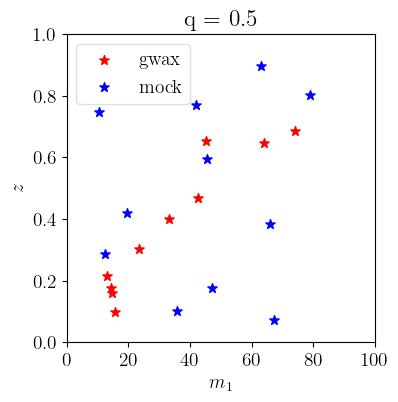

Number of events from gwax file with q~0.8: 58
Number of events from mock file with q~0.8: 68


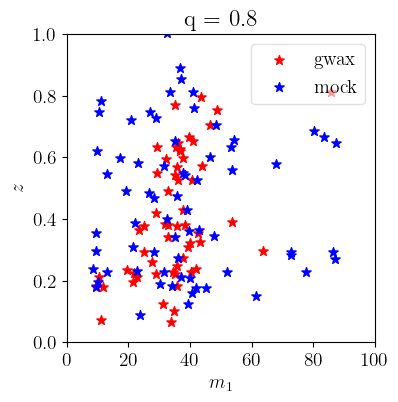

In [4]:

for qeval in [0.2, 0.5, 0.8]:
    fig, ax = plt.subplots(figsize=(4,4))
    ax.set(title=f"q = {qeval}")

    events_at_q_1 = np.abs(event_barycenters_1[:,2]-qeval) /qeval < 0.1
    print(f"Number of events from gwax file with q~{qeval}: {np.sum(events_at_q_1)}")
    ax.scatter(event_barycenters_1[events_at_q_1,0], event_barycenters_1[events_at_q_1,1],
               c='red', marker='*', s=7**2, zorder=2,
               label='gwax',
              )

    events_at_q_2 = np.abs(event_barycenters_2[:,2]-qeval) /qeval < 0.1
    print(f"Number of events from mock file with q~{qeval}: {np.sum(events_at_q_2)}")
    ax.scatter(event_barycenters_2[events_at_q_2,0], event_barycenters_1[events_at_q_2,1],
               c='blue', marker='*', s=7**2, zorder=2,
               label='mock',
              )

    # injections_at_q = np.abs(detected_injections[:,2]-q_grid[qeval_ind]) < 0.01
    # ax.scatter(detected_injections[injections_at_q,0], detected_injections[injections_at_q,1],
    #            c='r', marker='d', s=4**2, zorder=1,
    #            label='Detected injections',
    #           )
    ax.set_xlabel('$m_1$')
    ax.set_xlim(0,100)
    ax.set_ylabel('$z$')
    ax.set_ylim(0., 1.)
    ax.legend(loc='best', framealpha=0.6)
    ax.set_box_aspect(1)
    
    plt.show()
    plt.close()

Number of events from gwax file with z~0.2: 15
Number of events from mock file with z~0.2: 11


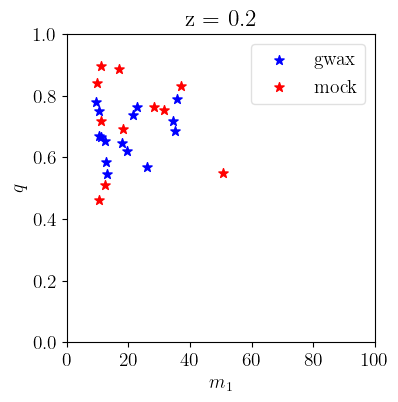

Number of events from gwax file with z~0.5: 12
Number of events from mock file with z~0.5: 14


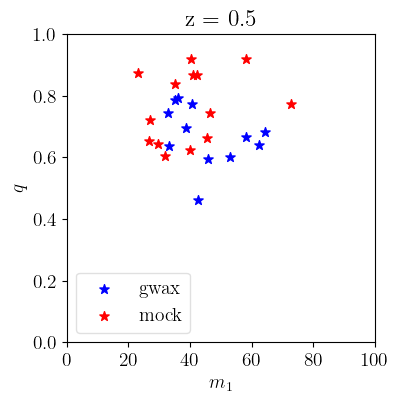

Number of events from gwax file with z~0.8: 20
Number of events from mock file with z~0.8: 14


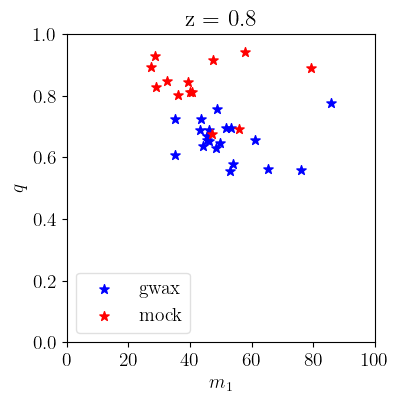

In [5]:

for zeval in [0.2, 0.5, 0.8]:
    fig, ax = plt.subplots(figsize=(4,4))
    ax.set(title=f"z = {zeval}")

    events_at_z_1 = np.abs(event_barycenters_1[:,1]-zeval) /zeval < 0.1
    print(f"Number of events from gwax file with z~{zeval}: {np.sum(events_at_z_1)}")
    ax.scatter(event_barycenters_1[events_at_z_1,0], event_barycenters_1[events_at_z_1,2],
               c='blue', marker='*', s=7**2, zorder=2,
               label=' gwax',
              )

    events_at_z_2 = np.abs(event_barycenters_2[:,1]-zeval) /zeval < 0.1
    print(f"Number of events from mock file with z~{zeval}: {np.sum(events_at_z_2)}")
    ax.scatter(event_barycenters_2[events_at_z_2,0], event_barycenters_2[events_at_z_2,2],
               c='red', marker='*', s=7**2, zorder=2,
               label='mock',
              )

    # injections_at_q = np.abs(detected_injections[:,2]-q_grid[qeval_ind]) < 0.01
    # ax.scatter(detected_injections[injections_at_q,0], detected_injections[injections_at_q,1],
    #            c='r', marker='d', s=4**2, zorder=1,
    #            label='Detected injections',
    #           )
    ax.set_xlabel('$m_1$')
    ax.set_xlim(0,100)
    ax.set_ylabel('$q$')
    ax.set_ylim(0., 1.)
    ax.legend(loc='best', framealpha=0.6)
    ax.set_box_aspect(1)
    
    plt.show()
    plt.close()

## Look at posterior distributions

In [6]:
n=3
nth_event_1 = observed_events_1[n*num_samples_1:(n+1)*num_samples_1,:3]
barycenter = np.median(nth_event_1,axis=0)
close_by = np.argmin((barycenter[0]-event_barycenters_2[:,0])**2 + (barycenter[1]-event_barycenters_2[:,1])**2 + (barycenter[2]-event_barycenters_2[:,2])**2)

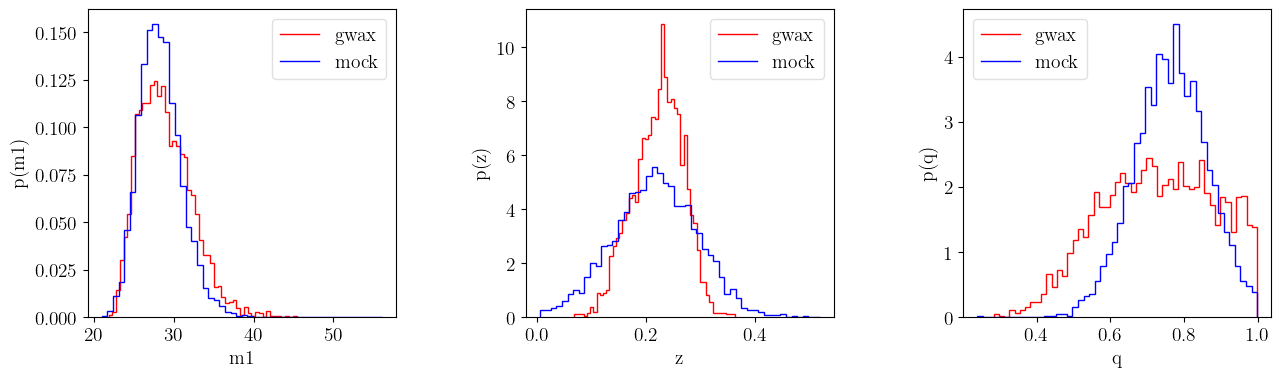

In [7]:
nbins=50

nth_event_2 = observed_events_2[close_by*num_samples_2:(close_by+1)*num_samples_2,:3]
fig, axes = plt.subplots(1, 3, figsize=(16,4))
for k,key in enumerate(parameter_keys_1[:3]):
    ax=axes[k]
    hist0, bins0 = np.histogram(nth_event_1[:,k], bins=nbins, density=True)
    hist1, bins1 = np.histogram(nth_event_2[:,k], bins=nbins, density=True)
    
    ax.stairs(hist0, bins0, color='r', label='gwax')
    ax.stairs(hist1, bins1, color='blue', label='mock')
    
    ax.set_xlabel(key)
    ax.set_ylabel(f"p({key})")
    ax.legend(loc='best', framealpha=0.6)
    ax.set_box_aspect(1)
        
plt.show()

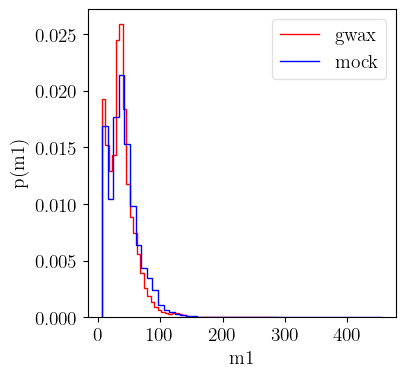

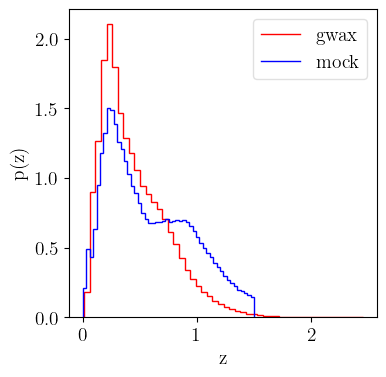

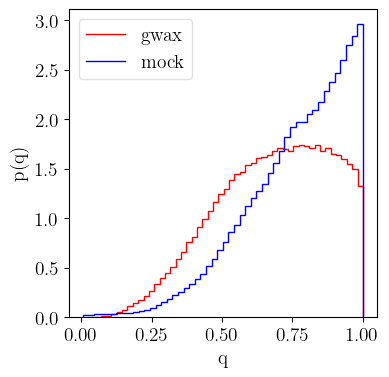

In [8]:
nbins=50

for k,key in enumerate(parameter_keys_1[:3]):
    
    fig, ax = plt.subplots(1, 1, figsize=(4,4))

    hist0, bins0 = np.histogram(observed_events_1[:,k], bins=nbins, density=True)
    hist1, bins1 = np.histogram(observed_events_2[:,k], bins=nbins, density=True)
    
    ax.stairs(hist0, bins0, color='r', label='gwax')
    ax.stairs(hist1, bins1, color='blue', label='mock')
    
    ax.set_xlabel(key)
    ax.set_ylabel(f"p({key})")
    ax.legend(loc='best', framealpha=0.6)
    ax.set_box_aspect(1)
    
    plt.show()

## Look at prior distributions

In [9]:
prior_nth_event_1 = event_priors_1[n*num_samples_1:(n+1)*num_samples_1]

In [10]:
prior_nth_event_2 = event_priors_2[close_by*num_samples_2:(close_by+1)*num_samples_2]

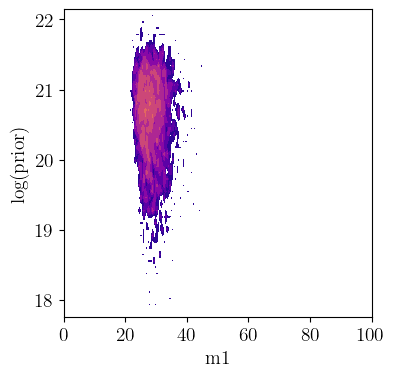

In [11]:
fig, ax = plt.subplots(1, 1, figsize=(4,4))

H, binsx0, binsy0 = np.histogram2d(nth_event_1[:,0], np.log(prior_nth_event_1), bins=nbins, density=True)

X, Y = np.meshgrid(binsx0[:-1], binsy0[:-1])
Hmin=H[H>0].min()
Hmax=H[H>0].max()
vmin = int(Hmin /10**int(np.log10(Hmin)-1))*10**(int(np.log10(Hmin))-1)
vmax = int(Hmax /10**int(np.log10(Hmax))+1)*10**int(np.log10(Hmax))
H[H==0] = 1e-32
cmap = plt.get_cmap('plasma')
norm = mpl.colors.LogNorm(vmin=vmin, vmax=vmax)
im = ax.contourf(X, Y, H.T,
                 levels=np.logspace(np.log10(vmin),np.log10(vmax),10),
                 cmap=cmap,
                 norm=norm,
                )

ax.set_xlabel('m1')
ax.set_xlim(0,100)
ax.set_ylabel('log(prior)')
ax.set_box_aspect(1)

plt.show()

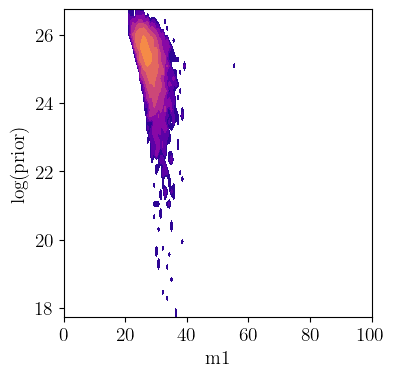

In [12]:
fig, ax = plt.subplots(1, 1, figsize=(4,4))

H, binsx0, binsy0 = np.histogram2d(nth_event_2[:,0], np.log(prior_nth_event_2), bins=nbins, density=True)

X, Y = np.meshgrid(binsx0[:-1], binsy0[:-1])
Hmin=H[H>0].min()
Hmax=H[H>0].max()
vmin = int(Hmin /10**int(np.log10(Hmin)-1))*10**(int(np.log10(Hmin))-1)
vmax = int(Hmax /10**int(np.log10(Hmax))+1)*10**int(np.log10(Hmax))
H[H==0] = 1e-32
cmap = plt.get_cmap('plasma')
norm = mpl.colors.LogNorm(vmin=vmin, vmax=vmax)
im = ax.contourf(X, Y, H.T,
                 levels=np.logspace(np.log10(vmin),np.log10(vmax),10),
                 cmap=cmap,
                 norm=norm,
                )

ax.set_xlabel('m1')
ax.set_xlim(0,100)
ax.set_ylabel('log(prior)')
ax.set_box_aspect(1)

plt.show()

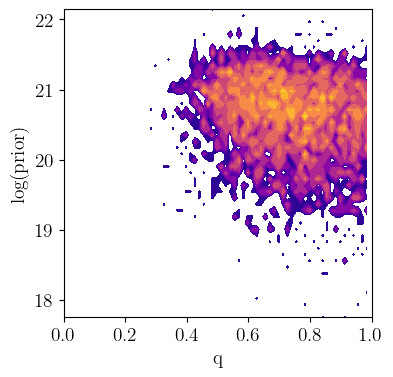

In [13]:
fig, ax = plt.subplots(1, 1, figsize=(4,4))

H, binsx0, binsy0 = np.histogram2d(nth_event_1[:,2], np.log(prior_nth_event_1), bins=nbins, density=True)

X, Y = np.meshgrid(binsx0[:-1], binsy0[:-1])
Hmin=H[H>0].min()
Hmax=H[H>0].max()
vmin = int(Hmin /10**int(np.log10(Hmin)-1))*10**(int(np.log10(Hmin))-1)
vmax = int(Hmax /10**int(np.log10(Hmax))+1)*10**int(np.log10(Hmax))
H[H==0] = 1e-32
cmap = plt.get_cmap('plasma')
norm = mpl.colors.LogNorm(vmin=vmin, vmax=vmax)
im = ax.contourf(X, Y, H.T,
                 levels=np.logspace(np.log10(vmin),np.log10(vmax),10),
                 cmap=cmap,
                 norm=norm,
                )

ax.set_xlabel('q')
ax.set_xlim(0,1)
ax.set_ylabel('log(prior)')
ax.set_box_aspect(1)

plt.show()

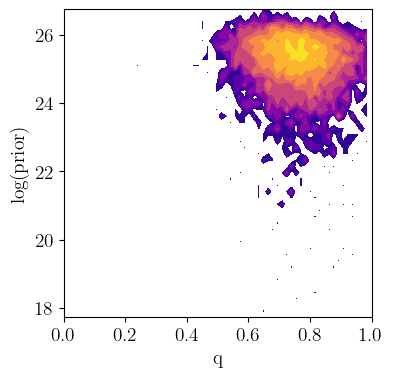

In [14]:
fig, ax = plt.subplots(1, 1, figsize=(4,4))

H, binsx0, binsy0 = np.histogram2d(nth_event_2[:,2], np.log(prior_nth_event_2), bins=nbins, density=True)

X, Y = np.meshgrid(binsx0[:-1], binsy0[:-1])
Hmin=H[H>0].min()
Hmax=H[H>0].max()
vmin = int(Hmin /10**int(np.log10(Hmin)-1))*10**(int(np.log10(Hmin))-1)
vmax = int(Hmax /10**int(np.log10(Hmax))+1)*10**int(np.log10(Hmax))
H[H==0] = 1e-32
cmap = plt.get_cmap('plasma')
norm = mpl.colors.LogNorm(vmin=vmin, vmax=vmax)
im = ax.contourf(X, Y, H.T,
                 levels=np.logspace(np.log10(vmin),np.log10(vmax),10),
                 cmap=cmap,
                 norm=norm,
                )

ax.set_xlabel('q')
ax.set_xlim(0,1)
ax.set_ylabel('log(prior)')
ax.set_box_aspect(1)

plt.show()

# Injections

In [15]:
injections_file = np.load("../gwax_samples/gwtc4_injections_full.npz")
detected_injections_1 = np.vstack(
    [injections_file[key + "s"] for key in parameter_keys_1]
).T
injection_priors_1 = injections_file["inj_priors"]
num_injections_1 = int(injections_file["ninjs"])

In [16]:
print('Total number of injections for GWTC-3: %.2e' %num_injections_1)
print('Number of detected injections for GWTC-3: %.2e' %detected_injections_1.shape[0])

Total number of injections for GWTC-3: 1.13e+09
Number of detected injections for GWTC-3: 1.07e+06


## From mock

In [17]:
injections_file = np.load("./injections/injections.npz")
detected_injections_2 = np.vstack(
    [injections_file[key + "s_inj"] for key in parameter_keys_2]
).T
injection_priors_2 = injections_file["priors_inj"]
num_injections_2 = int(injections_file["ninj"])

In [18]:
print('Total number of injections for GWTC-3: %.2e' %num_injections_2)
print('Number of detected injections for GWTC-3: %.2e' %detected_injections_2.shape[0])

Total number of injections for GWTC-3: 3.00e+06
Number of detected injections for GWTC-3: 1.19e+05


## Look at posterior distributions

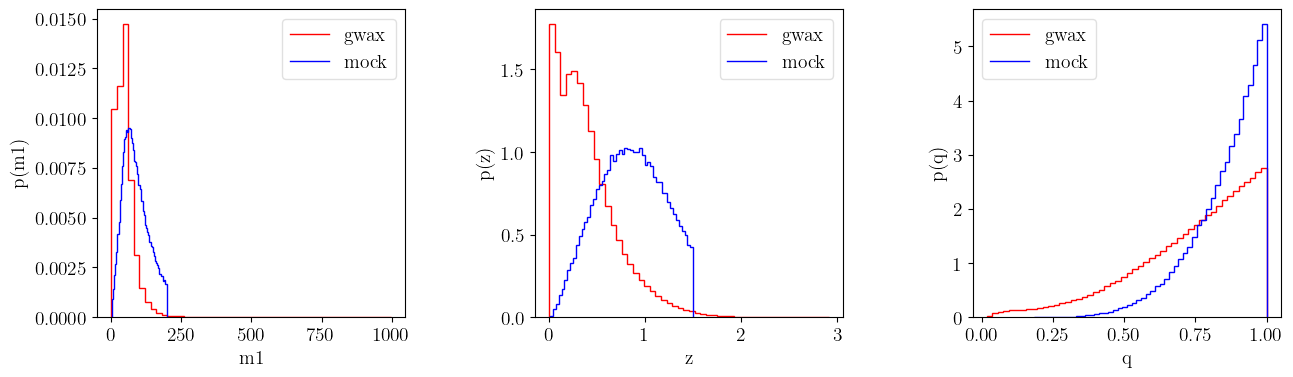

In [19]:
nbins=50

fig, axes = plt.subplots(1, 3, figsize=(16,4))

for k,key in enumerate(parameter_keys_2):
    ax=axes[k]

    hist0, bins0 = np.histogram(detected_injections_1[:,k], bins=nbins, density=True)
    hist1, bins1 = np.histogram(detected_injections_2[:,k], bins=nbins, density=True)
    
    ax.stairs(hist0, bins0, color='r', label='gwax')
    ax.stairs(hist1, bins1, color='blue', label='mock')
    
    ax.set_xlabel(key)
    ax.set_ylabel(f"p({key})")
    ax.legend(loc='best', framealpha=0.6)
    ax.set_box_aspect(1)
    
plt.show()

## Look at prior distributions

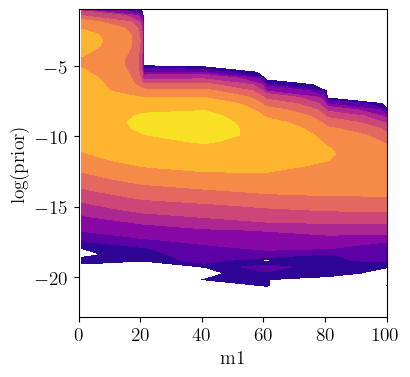

In [20]:
fig, ax = plt.subplots(1, 1, figsize=(4,4))

H, binsx0, binsy0 = np.histogram2d(detected_injections_1[:,0], np.log(injection_priors_1), bins=nbins, density=True)

X, Y = np.meshgrid(binsx0[:-1], binsy0[:-1])
Hmin=H[H>0].min()
Hmax=H[H>0].max()
vmin = int(Hmin /10**int(np.log10(Hmin)-1))*10**(int(np.log10(Hmin))-1)
vmax = int(Hmax /10**int(np.log10(Hmax))+1)*10**int(np.log10(Hmax))
H[H==0] = 1e-32
cmap = plt.get_cmap('plasma')
norm = mpl.colors.LogNorm(vmin=vmin, vmax=vmax)
im = ax.contourf(X, Y, H.T,
                 levels=np.logspace(np.log10(vmin),np.log10(vmax),10),
                 cmap=cmap,
                 norm=norm,
                )

ax.set_xlabel('m1')
ax.set_xlim(0,100)
ax.set_ylabel('log(prior)')
ax.set_box_aspect(1)

plt.show()

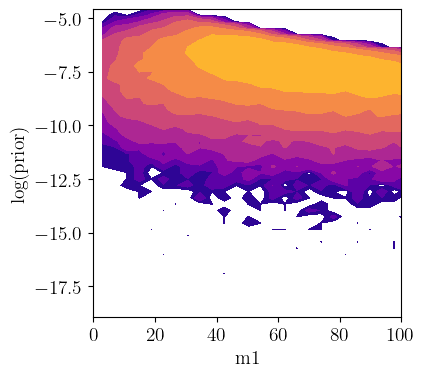

In [21]:
fig, ax = plt.subplots(1, 1, figsize=(4,4))

H, binsx0, binsy0 = np.histogram2d(detected_injections_2[:,0], np.log(injection_priors_2), bins=nbins, density=True)

X, Y = np.meshgrid(binsx0[:-1], binsy0[:-1])
Hmin=H[H>0].min()
Hmax=H[H>0].max()
vmin = int(Hmin /10**int(np.log10(Hmin)-1))*10**(int(np.log10(Hmin))-1)
vmax = int(Hmax /10**int(np.log10(Hmax))+1)*10**int(np.log10(Hmax))
H[H==0] = 1e-32
cmap = plt.get_cmap('plasma')
norm = mpl.colors.LogNorm(vmin=vmin, vmax=vmax)
im = ax.contourf(X, Y, H.T,
                 levels=np.logspace(np.log10(vmin),np.log10(vmax),10),
                 cmap=cmap,
                 norm=norm,
                )

ax.set_xlabel('m1')
ax.set_xlim(0,100)
ax.set_ylabel('log(prior)')
ax.set_box_aspect(1)

plt.show()

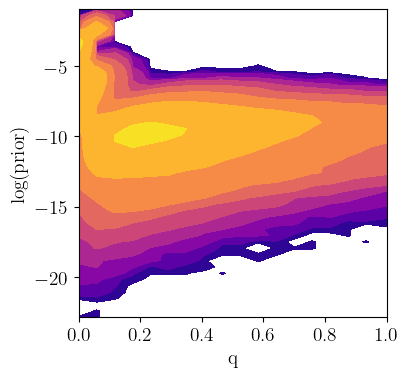

In [22]:
fig, ax = plt.subplots(1, 1, figsize=(4,4))

H, binsx0, binsy0 = np.histogram2d(detected_injections_1[:,1], np.log(injection_priors_1), bins=nbins, density=True)

X, Y = np.meshgrid(binsx0[:-1], binsy0[:-1])
Hmin=H[H>0].min()
Hmax=H[H>0].max()
vmin = int(Hmin /10**int(np.log10(Hmin)-1))*10**(int(np.log10(Hmin))-1)
vmax = int(Hmax /10**int(np.log10(Hmax))+1)*10**int(np.log10(Hmax))
H[H==0] = 1e-32
cmap = plt.get_cmap('plasma')
norm = mpl.colors.LogNorm(vmin=vmin, vmax=vmax)
im = ax.contourf(X, Y, H.T,
                 levels=np.logspace(np.log10(vmin),np.log10(vmax),10),
                 cmap=cmap,
                 norm=norm,
                )

ax.set_xlabel('q')
ax.set_xlim(0,1)
ax.set_ylabel('log(prior)')
ax.set_box_aspect(1)

plt.show()

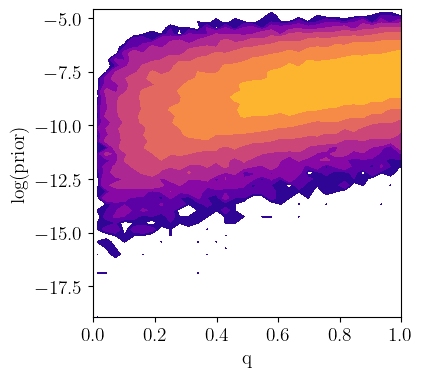

In [23]:
fig, ax = plt.subplots(1, 1, figsize=(4,4))

H, binsx0, binsy0 = np.histogram2d(detected_injections_2[:,1], np.log(injection_priors_2), bins=nbins, density=True)

X, Y = np.meshgrid(binsx0[:-1], binsy0[:-1])
Hmin=H[H>0].min()
Hmax=H[H>0].max()
vmin = int(Hmin /10**int(np.log10(Hmin)-1))*10**(int(np.log10(Hmin))-1)
vmax = int(Hmax /10**int(np.log10(Hmax))+1)*10**int(np.log10(Hmax))
H[H==0] = 1e-32
cmap = plt.get_cmap('plasma')
norm = mpl.colors.LogNorm(vmin=vmin, vmax=vmax)
im = ax.contourf(X, Y, H.T,
                 levels=np.logspace(np.log10(vmin),np.log10(vmax),10),
                 cmap=cmap,
                 norm=norm,
                )

ax.set_xlabel('q')
ax.set_xlim(0,1)
ax.set_ylabel('log(prior)')
ax.set_box_aspect(1)

plt.show()